## Credit Card Fraud

personal challenge: use more OOP for practice

# Imports and loading dataset

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from xgboost import XGBClassifier

In [2]:
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)


train_df = pd.read_csv('/Users/gabrielaslomiany/PycharmProjects/Not-So-Small-ML/Credit Card Fraud/data/train.csv')
test_df = pd.read_csv('/Users/gabrielaslomiany/PycharmProjects/Not-So-Small-ML/Credit Card Fraud/data/test.csv')

print('train shape:', train_df.shape)
print('test shape:', test_df.shape)
train_df.head()

train shape: (699960, 26)
test shape: (299984, 25)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


# Checking training set

In [3]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [4]:
train_df.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [5]:
train_df.isna().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

In [14]:
list(train_df.columns)

['id',
 'amount_usd',
 'hours_since_last_txn',
 'txn_count_last_24h',
 'distance_from_home_km',
 'card_age_months',
 'customer_age',
 'account_balance_usd',
 'cvv_retry_count',
 'velocity_score',
 'time_of_day_hour',
 'day_of_week',
 'merchant_risk_score',
 'prior_disputes',
 'merchant_category',
 'card_type',
 'auth_method',
 'channel',
 'device_type',
 'is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt',
 'is_fraud']

In [6]:
train_df.isna().sum().sum()

np.int64(0)

In [7]:
train_df.duplicated().sum()

np.int64(0)

## Data processing
This step includes handling missing values, normalizing data, and encoding categorical variables.

#### Checking unique values

In [8]:
print(train_df['merchant_category'].unique())
print(train_df['card_type'].unique())
print(train_df['auth_method'].unique())
print(train_df['channel'].unique())
print(train_df['device_type'].unique())

<StringArray>
[      'Groceries',   'Online Retail',       'Utilities',     'Electronics',
      'Healthcare',     'Restaurants',            'Fuel',       'Streaming',
 'Crypto Exchange',          'Gaming',          'Travel',      'Gift Cards']
Length: 12, dtype: str
<StringArray>
['Mastercard', 'Visa', 'Amex', 'RuPay', 'Discover']
Length: 5, dtype: str
<StringArray>
['OTP', 'PIN', '3D Secure', 'Biometric', 'No Authentication']
Length: 5, dtype: str
<StringArray>
['POS', 'In-App', 'Online', 'ATM', 'Contactless']
Length: 5, dtype: str
<StringArray>
[       'iPhone', 'Android Phone',        'Tablet',    'Windows PC',
  'POS Terminal',           'Mac',   'ATM Machine',   'Smart Watch']
Length: 8, dtype: str


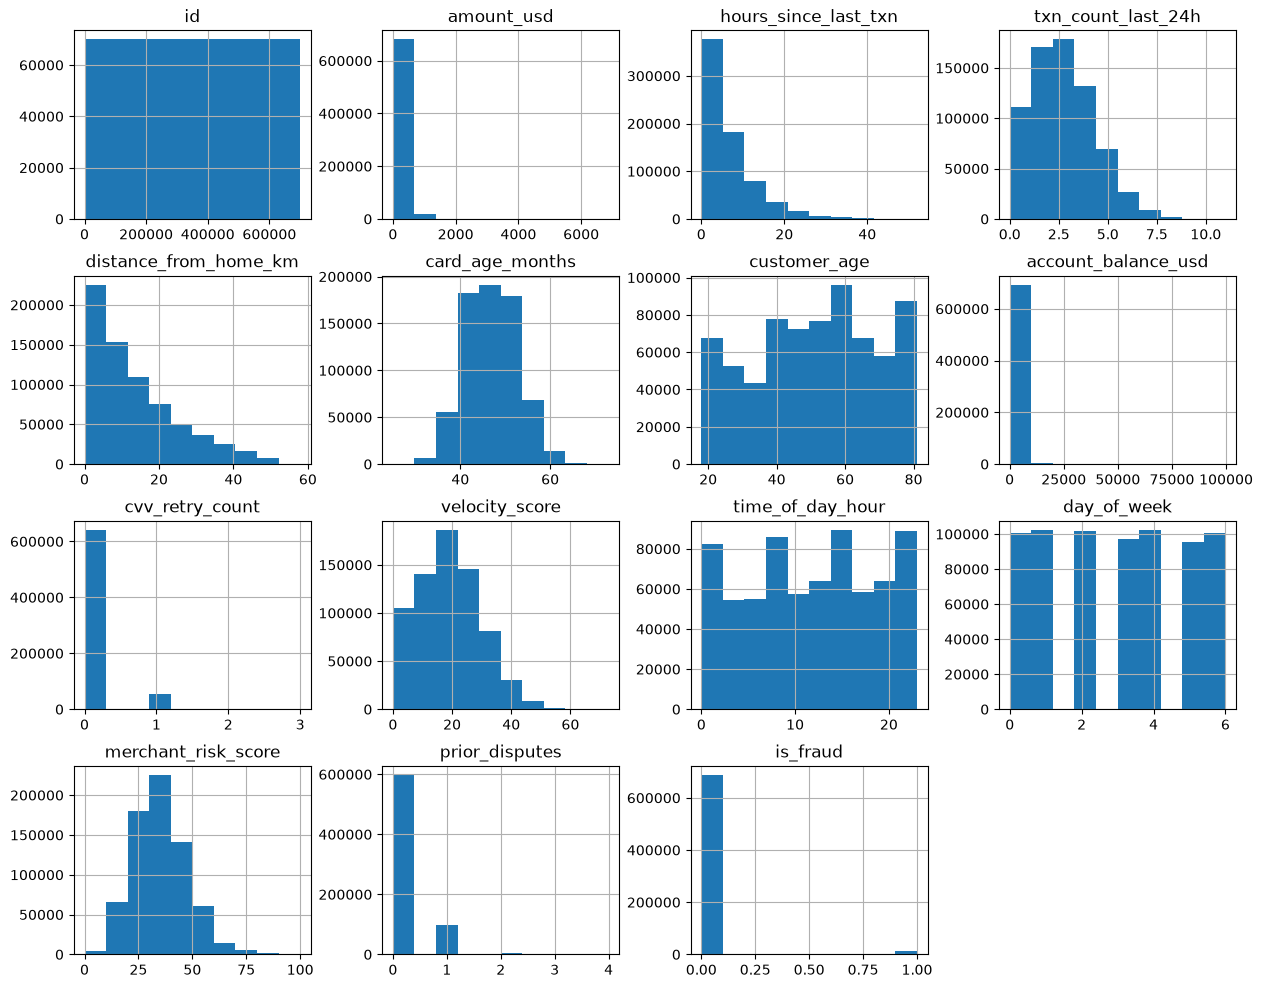

In [13]:
train_df.hist(figsize=(15,12))
plt.show()

Fraud rate: 0.0167


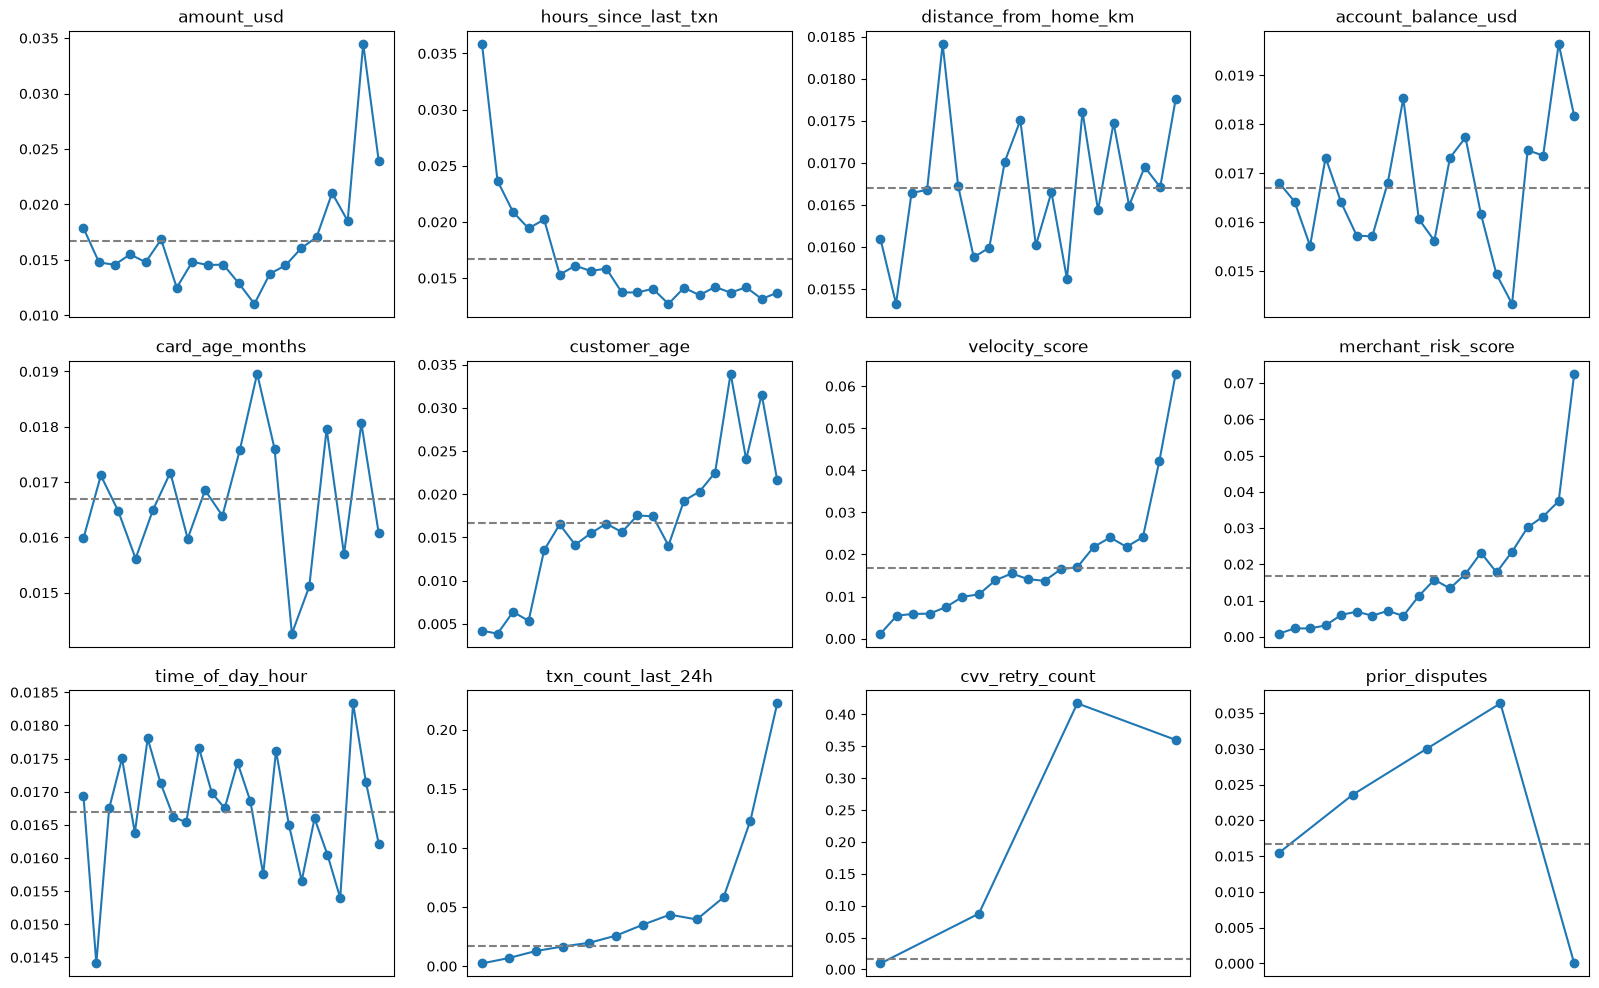

In [19]:
num_cols = ["amount_usd", "hours_since_last_txn", "distance_from_home_km",
            "account_balance_usd", "card_age_months", "customer_age",
            "velocity_score", "merchant_risk_score", "time_of_day_hour",
            "txn_count_last_24h", "cvv_retry_count", "prior_disputes"]

print(f"Fraud rate: {train_df['is_fraud'].mean():.4f}")

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), num_cols):
    s = train_df[c]
    bins = s if s.nunique() <= 25 else pd.qcut(s, 20, duplicates="drop")
    rate = train_df.groupby(bins, observed=True)["is_fraud"].mean()
    ax.plot(range(len(rate)), rate.values, marker="o")
    ax.axhline(train_df["is_fraud"].mean(), ls="--", c="grey")
    ax.set_title(c)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

## Fraud rate by feature value (univariate target analysis)

### What was done
The raw histograms only show how each feature is distributed. They say nothing about how it relates to fraud. To check that, I computed the **fraud rate per bin** for every numeric feature:

- **Continuous features** were split into 20 quantile bins (`pd.qcut`), so each bin holds roughly 5% of the training rows. With quantile bins, the rate in each bin is estimated from a similar sample size, even for heavily skewed features like `amount_usd`.
- **Discrete features** with at most 25 unique values (`cvv_retry_count`, `prior_disputes`, `txn_count_last_24h`) were grouped by their raw values.
- For each bin: $\hat{p}_{\text{bin}} = \frac{\#\,\text{fraud in bin}}{\#\,\text{rows in bin}}$
- The dashed line is the global fraud rate, $\hat{p} \approx 0.0167$. The x-axis runs from low to high feature values.

**Why:** a feature is useful if its fraud rate moves away from the baseline. A flat line means little signal on its own. A steady rise or fall means a strong feature, and a sharp jump points to a threshold worth turning into a flag.

## Feature engineering

In [16]:
# Amounts
train_df["is_round_amount"] = (train_df["amount_usd"] % 10 == 0).astype(int)
train_df["is_small_amount"] = (train_df["amount_usd"] < 5).astype(int)

# Velocity / time
train_df["is_weekend"] = (train_df["day_of_week"] >= 5).astype(int)

# Risk flags
train_df["cvv_retry_high"] = (train_df["cvv_retry_count"] >= 2).astype(int)

# Profile
train_df["new_card"] = (train_df["card_age_months"] < 3).astype(int)

In [17]:
train_df.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,is_weekend,cvv_retry_high,new_card,is_round_amount,is_small_amount
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0,0,0,0,0,0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0,1,0,0,0,0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0,0,0,0,0,0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0,0,0,0,0,0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0,0,0,0,0,0


## Scaling & Train test

In [20]:
X = train_df.drop(columns=['is_fraud'])
y = train_df['is_fraud']
print('Features:', X.shape[1])
print('Target stats:')
print(y.describe().round(2))

Features: 30
Target stats:
count    699960.00
mean          0.02
std           0.13
min           0.00
25%           0.00
50%           0.00
75%           0.00
max           1.00
Name: is_fraud, dtype: float64


In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1111)

In [27]:
X_train.dtypes

id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool


In [29]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Train:", X_train_prep.shape, "Test:", X_test_prep.shape)

Train: (559968, 60) Test: (139992, 60)
